# Evidence-Grounded Claim Verification: Retrieval + NLI vs. LLM

A retrieve-then-verify fact-checking pipeline, benchmarked on **SciFact**: 1,409 expert-written scientific claims checked against a corpus of 5,183 research abstracts.

**Pipeline:** claim → retrieve abstracts (BM25 / dense / hybrid) → select evidence sentences (cross-encoder) → verifier → `SUPPORT` / `CONTRADICT` / `NEI` (not enough info)

**Verifiers compared on exactly the same evidence:**
1. Zero-shot NLI model (DeBERTa-v3-base, trained on MNLI / FEVER-NLI / ANLI)
2. The same NLI model fine-tuned on SciFact's training claims
3. An LLM given the retrieved evidence
4. The same LLM with no evidence (closed-book), to measure what retrieval adds


## 0. Setup

In [1]:
!pip -q install rank_bm25 faiss-cpu sentence-transformers sentencepiece protobuf openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 97.7 MB/s eta 0:00:00


In [2]:
import os, re, json, time, random, math, tarfile, urllib.request, collections, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from rank_bm25 import BM25Okapi
import faiss

try:
    display
except NameError:  # outside Jupyter
    display = print

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUT = "results"
os.makedirs(OUT, exist_ok=True)
LABELS = ["SUPPORT", "CONTRADICT", "NEI"]

# ---- Config ----
DENSE_MODEL = "BAAI/bge-small-en-v1.5"
BGE_QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
RERANK_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
NLI_MODEL = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"
TOP_DOCS = 3            # abstracts passed on to sentence selection
TOP_SENTS = 3           # evidence sentences passed on to the verifier
N_VAL = 100             # training claims held out for tuning (never tune on the test set)
FT_SEEDS = [42, 43, 44] # fine-tuning runs
FT_EPOCHS = 2
FT_LR = 2e-5
FT_BATCH = 16
MAX_LEN = 256

In [3]:
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none (switch the runtime to T4 GPU)")

Device: cuda | GPU: Tesla T4


## 1. Data
**What:** downloads SciFact and turns each claim into one label plus its gold evidence (which abstracts and which sentences).

**Why these splits:** SciFact's official test labels are hidden for its leaderboard, so the 300 labelled **dev** claims are our test set. 100 training claims are held out as a **validation** set; every threshold and model choice is made on validation, never on test.

train: 809 claims, dropped 0 with mixed labels
dev: 300 claims, dropped 0 with mixed labels
Corpus: 5183 abstracts


,train,val,test
SUPPORT,291,41,124
CONTRADICT,152,21,64
NEI,266,38,112


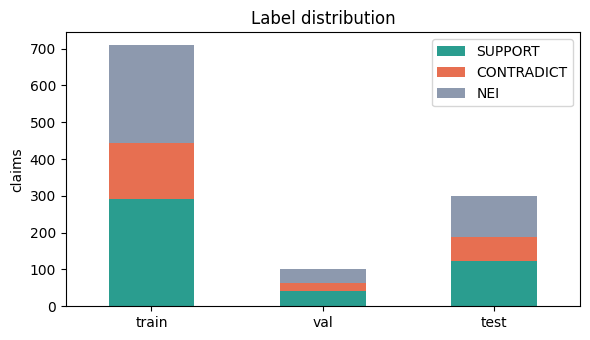

In [4]:
DATA_URL = "https://scifact.s3-us-west-2.amazonaws.com/release/latest/data.tar.gz"
if not os.path.exists("data/corpus.jsonl"):
    urllib.request.urlretrieve(DATA_URL, "data.tar.gz")
    with tarfile.open("data.tar.gz") as t:
        try:
            t.extractall(".", filter="data")
        except TypeError:
            t.extractall(".")

def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]

corpus = {d["doc_id"]: d for d in read_jsonl("data/corpus.jsonl")}
doc_ids = list(corpus)

def prep(c):
    ev = c.get("evidence") or {}
    labels = {r["label"] for rs in ev.values() for r in rs}
    label = "NEI" if not labels else (labels.pop() if len(labels) == 1 else None)
    return dict(
        id=c["id"],
        claim=c["claim"],
        label=label,  # None = evidence both supports and contradicts (dropped below)
        gold_docs={int(d) for d in ev},
        gold_sents={(int(d), s) for d, rs in ev.items() for r in rs for s in r["sentences"]},
        rationales=[(int(d), r["sentences"], r["label"]) for d, rs in ev.items() for r in rs],
    )

def load_split(name):
    claims = [prep(c) for c in read_jsonl(f"data/claims_{name}.jsonl")]
    kept = [c for c in claims if c["label"] is not None]
    print(f"{name}: {len(claims)} claims, dropped {len(claims) - len(kept)} with mixed labels")
    return kept

train_all = load_split("train")
test_claims = load_split("dev")
random.Random(SEED).shuffle(test_claims)  # so any prefix subset is a random sample

train_claims, val_claims = train_test_split(
    train_all, test_size=N_VAL, random_state=SEED, stratify=[c["label"] for c in train_all]
)
all_claims = train_claims + val_claims + test_claims

dist = pd.DataFrame(
    {name: pd.Series([c["label"] for c in cl]).value_counts().reindex(LABELS, fill_value=0)
     for name, cl in [("train", train_claims), ("val", val_claims), ("test", test_claims)]}
)
print(f"Corpus: {len(corpus)} abstracts")
display(dist)

ax = dist.T.plot(kind="bar", stacked=True, figsize=(6, 3.5), color=["#2a9d8f", "#e76f51", "#8d99ae"])
ax.set_ylabel("claims"); ax.set_title("Label distribution"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(f"{OUT}/label_distribution.png", dpi=150); plt.show()

## 2. Retrieval: BM25 vs. dense vs. hybrid
**What:** three ways to find the abstracts most relevant to a claim.
- **BM25:** classic keyword matching. Strong when the claim reuses the abstract's exact terms.
- **Dense:** embeds claims and abstracts with `bge-small-en-v1.5` and searches a FAISS index by cosine similarity. Catches paraphrases that share no words.
- **Hybrid:** merges both rankings with Reciprocal Rank Fusion, `score = Σ 1/(60 + rank)`. No score calibration needed.

**Metric:** Recall@k is the fraction of a claim's gold abstracts that appear in the top k, averaged over claims that have evidence. The retriever used downstream is picked by **validation** Recall@3.

In [5]:
TOKEN_RE = re.compile(r"[a-z0-9]+")
def tokenize(text):
    return [w for w in TOKEN_RE.findall(text.lower()) if w not in ENGLISH_STOP_WORDS]

doc_texts = [corpus[d]["title"] + ". " + " ".join(corpus[d]["abstract"]) for d in doc_ids]
bm25 = BM25Okapi([tokenize(t) for t in doc_texts])

def bm25_search(query, k=100):
    scores = bm25.get_scores(tokenize(query))
    return [doc_ids[i] for i in np.argsort(-scores)[:k]]

def rrf(rankings, k=60, top=100):
    scores = collections.defaultdict(float)
    for ranking in rankings:
        for r, d in enumerate(ranking):
            scores[d] += 1.0 / (k + r + 1)
    return [d for d, _ in sorted(scores.items(), key=lambda x: -x[1])[:top]]

In [6]:
from sentence_transformers import SentenceTransformer, CrossEncoder
dense_model = SentenceTransformer(DENSE_MODEL, device=DEVICE)
reranker = CrossEncoder(RERANK_MODEL, device=DEVICE)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [7]:
doc_emb = dense_model.encode(doc_texts, batch_size=64, normalize_embeddings=True,
                             show_progress_bar=True, convert_to_numpy=True).astype("float32")
index = faiss.IndexFlatIP(doc_emb.shape[1])  # inner product on unit vectors = cosine similarity
index.add(doc_emb)

def dense_search(queries, k=100):
    q = dense_model.encode([BGE_QUERY_PREFIX + x for x in queries], batch_size=64,
                           normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    _, I = index.search(q, k)
    return [[doc_ids[i] for i in row] for row in I]

def retrieve(claims):
    dense = dense_search([c["claim"] for c in claims])
    for c, dr in zip(claims, dense):
        br = bm25_search(c["claim"])
        c["rank"] = {"bm25": br, "dense": dr, "hybrid": rrf([br, dr])}

t0 = time.time()
retrieve(all_claims)
print(f"Retrieved for {len(all_claims)} claims in {time.time() - t0:.1f}s")

RETRIEVERS = {"bm25": "BM25", "dense": "Dense (bge-small + FAISS)", "hybrid": "Hybrid (RRF)"}

def recall_at_k(claims, method, k):
    vals = [len(set(c["rank"][method][:k]) & c["gold_docs"]) / len(c["gold_docs"])
            for c in claims if c["gold_docs"]]
    return float(np.mean(vals))

retrieval_rows = []
for split, cl in [("val", val_claims), ("test", test_claims)]:
    for m, name in RETRIEVERS.items():
        row = {"Split": split, "Retriever": name}
        row.update({f"Recall@{k}": recall_at_k(cl, m, k) for k in (1, 3, 5, 10)})
        retrieval_rows.append(row)
retrieval_df = pd.DataFrame(retrieval_rows)
display(retrieval_df.round(3))

val_r = {m: recall_at_k(val_claims, m, TOP_DOCS) for m in RETRIEVERS}
BEST_RETRIEVER = max(val_r, key=val_r.get)
print(f"Using {RETRIEVERS[BEST_RETRIEVER]} downstream (best validation Recall@{TOP_DOCS} = {val_r[BEST_RETRIEVER]:.3f})")

Batches:   0%|          | 0/81 [00:00<?, ?it/s]

Retrieved for 1109 claims in 14.1s


,Split,Retriever,Recall@1,Recall@3,Recall@5,Recall@10
0,val,BM25,0.565,0.722,0.843,0.879
1,val,Dense (bge-small + FAISS),0.810,0.911,0.931,0.984
2,val,Hybrid (RRF),0.661,0.859,0.899,0.952
3,test,BM25,0.712,0.832,0.865,0.936
4,test,Dense (bge-small + FAISS),0.744,0.859,0.898,0.957
5,test,Hybrid (RRF),0.741,0.867,0.917,0.953


Using Dense (bge-small + FAISS) downstream (best validation Recall@3 = 0.911)


## 3. Evidence sentence selection
**What:** abstracts are long, but the proof is usually in one or two sentences. Every sentence of the top-3 abstracts is scored against the claim with a **cross-encoder**, which reads claim and sentence together (slower but more accurate than embeddings). The best 3 sentences become the evidence.

**Metric:** *evidence hit rate*, how often at least one gold rationale sentence survives this step. If it isn't here, no verifier can cite it.

In [8]:
def select_evidence(claims, method):
    pairs, meta = [], []
    for ci, c in enumerate(claims):
        for d in c["rank"][method][:TOP_DOCS]:
            for si, s in enumerate(corpus[d]["abstract"]):
                pairs.append((c["claim"], s))
                meta.append((ci, d, si))
    scores = reranker.predict(pairs, batch_size=128, show_progress_bar=len(pairs) > 1000) if pairs else []
    per_claim = collections.defaultdict(list)
    for (ci, d, si), sc in zip(meta, scores):
        per_claim[ci].append((float(sc), d, si))
    for ci, c in enumerate(claims):
        top = sorted(per_claim[ci], key=lambda x: -x[0])[:TOP_SENTS]
        c["evidence"] = [dict(doc=d, sent=si, text=corpus[d]["abstract"][si], score=sc) for sc, d, si in top]

t0 = time.time()
select_evidence(all_claims, BEST_RETRIEVER)
print(f"Selected evidence for {len(all_claims)} claims in {time.time() - t0:.1f}s")

def evidence_hit_rate(claims):
    ev = [c for c in claims if c["gold_sents"]]
    return float(np.mean([any((e["doc"], e["sent"]) in c["gold_sents"] for e in c["evidence"]) for c in ev]))

def doc_hit_rate(claims):
    ev = [c for c in claims if c["gold_docs"]]
    return float(np.mean([bool(set(c["rank"][BEST_RETRIEVER][:TOP_DOCS]) & c["gold_docs"]) for c in ev]))

for split, cl in [("val", val_claims), ("test", test_claims)]:
    print(f"{split}: gold abstract in top-{TOP_DOCS}: {doc_hit_rate(cl):.1%} | "
          f"gold sentence in top-{TOP_SENTS} evidence: {evidence_hit_rate(cl):.1%}")

example = next(c for c in test_claims if c["label"] == "SUPPORT")
print("\nExample claim:", example["claim"])
for e in example["evidence"]:
    print(f"  [{'GOLD' if (e['doc'], e['sent']) in example['gold_sents'] else '    '}] {e['text'][:150]}")

Batches:   0%|          | 0/240 [00:00<?, ?it/s]

Selected evidence for 1109 claims in 29.0s
val: gold abstract in top-3: 91.9% | gold sentence in top-3 evidence: 72.6%
test: gold abstract in top-3: 87.2% | gold sentence in top-3 evidence: 72.3%

Example claim: Tetraspanin-3 is a causative factor in the development of acute myelogenous leukemia
  [    ] Here, we show that Tetraspanin 3 is a target of the RNA binding protein Musashi 2, which plays a key role in AML.
  [    ] Acute Myelogenous Leukemia (AML) is an aggressive cancer that strikes both adults and children and is frequently resistant to therapy.
  [    ] BACKGROUND Increased expression of the tetraspanin TSPAN7 has been observed in a number of cancers; however, it is unclear how TSPAN7 plays a role in 


## 4. Verifier A: zero-shot NLI
**What:** Natural Language Inference asks whether a *premise* entails, contradicts, or is neutral towards a *hypothesis*. Each evidence sentence is a premise and the claim is the hypothesis:
entailment → `SUPPORT`, contradiction → `CONTRADICT`, otherwise `NEI`.

**Aggregation:** take the strongest entailment or contradiction score across the 3 sentences. If it's below a threshold τ, answer `NEI`. τ is tuned for macro-F1 on **validation**. The sentence that produced the verdict is the cited evidence.

In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

try:
    nli_tok = AutoTokenizer.from_pretrained(NLI_MODEL)
except Exception as e:  # fall back to the slow (sentencepiece) tokenizer
    print("Fast tokenizer failed, using slow one:", str(e)[:120])
    nli_tok = AutoTokenizer.from_pretrained(NLI_MODEL, use_fast=False)
nli_zs = AutoModelForSequenceClassification.from_pretrained(NLI_MODEL).to(DEVICE).eval()
id2label = {int(i): l.lower() for i, l in nli_zs.config.id2label.items()}
ENT = next(i for i, l in id2label.items() if l.startswith("entail"))
NEU = next(i for i, l in id2label.items() if l.startswith("neutral"))
CON = next(i for i, l in id2label.items() if l.startswith("contradict"))
print("Label ids:", id2label)

@torch.no_grad()
def nli_probs(model, premises, hypotheses, bs=32):
    model.eval()
    out = []
    for i in range(0, len(premises), bs):
        enc = nli_tok(premises[i:i + bs], hypotheses[i:i + bs], truncation=True,
                      max_length=MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
        out.append(torch.softmax(model(**enc).logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(out) if out else np.zeros((0, 3))

def free_gpu():
    import gc
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.28k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Label ids: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


In [10]:
def nli_scores(model, claims):
    prem, hyp, owner = [], [], []
    for ci, c in enumerate(claims):
        for j, e in enumerate(c["evidence"]):
            prem.append(e["text"]); hyp.append(c["claim"]); owner.append((ci, j))
    t0 = time.time()
    P = nli_probs(model, prem, hyp)
    per_claim_s = (time.time() - t0) / max(len(claims), 1)
    S = [np.zeros((len(c["evidence"]), 3)) for c in claims]
    for (ci, j), p in zip(owner, P):
        S[ci][j] = p
    return S, per_claim_s

def nli_decide(S_c, tau):
    if len(S_c) == 0:
        return "NEI", [], 0.0
    ent, con = S_c[:, ENT], S_c[:, CON]
    je, jc = int(ent.argmax()), int(con.argmax())
    if max(ent[je], con[jc]) < tau:
        return "NEI", [], float(1 - max(ent[je], con[jc]))
    return ("SUPPORT", [je], float(ent[je])) if ent[je] >= con[jc] else ("CONTRADICT", [jc], float(con[jc]))

TAU_GRID = np.round(np.arange(0.30, 0.96, 0.05), 2)
def tune_tau(S, claims):
    gold = [c["label"] for c in claims]
    f1 = lambda t: f1_score(gold, [nli_decide(s, t)[0] for s in S], labels=LABELS, average="macro", zero_division=0)
    return float(max(TAU_GRID, key=f1))

def nli_predict(S, claims, tau):
    preds = []
    for s, c in zip(S, claims):
        label, idx, conf = nli_decide(s, tau)
        preds.append(dict(label=label, cited={(c["evidence"][j]["doc"], c["evidence"][j]["sent"]) for j in idx}, conf=conf))
    return preds

S_val, _ = nli_scores(nli_zs, val_claims)
tau_zs = tune_tau(S_val, val_claims)
S_test, zs_latency = nli_scores(nli_zs, test_claims)
preds = {"NLI zero-shot": nli_predict(S_test, test_claims, tau_zs)}
latency = {"NLI zero-shot": zs_latency}
print(f"Zero-shot NLI: tau = {tau_zs} (tuned on validation)")

Zero-shot NLI: tau = 0.9 (tuned on validation)


## 5. Verifier B: fine-tuned NLI
**What:** the SciFact authors found that models trained on Wikipedia or news do noticeably worse on scientific claims than models adapted to the domain. This tests that finding by fine-tuning the same DeBERTa model on SciFact's training claims.

**Training pairs:**
- Gold rationale sentences (individually and joined) labelled entailment or contradiction.
- **Hard negatives** labelled neutral: sentences the pipeline itself retrieved that are *not* rationales. These match what the model sees at test time.

Negatives are capped at 1.5× positives. Each seed is a separate run, and the table reports mean ± std across seeds.

In [11]:
def build_ft_examples(claims, seed):
    rng = random.Random(seed)
    lab2id = {"SUPPORT": ENT, "CONTRADICT": CON}
    pos, neg = [], []
    for c in claims:
        for d, sents, lab in c["rationales"]:
            abstract = corpus[d]["abstract"]
            sents = [s for s in sents if s < len(abstract)]
            if not sents:
                continue
            pos.append((" ".join(abstract[s] for s in sents), c["claim"], lab2id[lab]))
            if len(sents) > 1:
                pos.extend((abstract[s], c["claim"], lab2id[lab]) for s in sents)
        for e in c["evidence"]:
            if (e["doc"], e["sent"]) not in c["gold_sents"]:
                neg.append((e["text"], c["claim"], NEU))
    rng.shuffle(neg)
    neg = neg[: int(1.5 * len(pos))]
    data = pos + neg
    rng.shuffle(data)
    return data, len(pos), len(neg)

In [12]:
def finetune(seed):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    data, n_pos, n_neg = build_ft_examples(train_claims, seed)
    model = AutoModelForSequenceClassification.from_pretrained(NLI_MODEL).float().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=0.01)
    steps_per_epoch = math.ceil(len(data) / FT_BATCH)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * FT_EPOCHS * steps_per_epoch), FT_EPOCHS * steps_per_epoch)
    use_amp = DEVICE == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    model.train()
    for ep in range(FT_EPOCHS):
        random.Random(seed + ep).shuffle(data)
        total = 0.0
        for i in range(0, len(data), FT_BATCH):
            batch = data[i:i + FT_BATCH]
            enc = nli_tok([x[0] for x in batch], [x[1] for x in batch], truncation=True,
                          max_length=MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
            y = torch.tensor([x[2] for x in batch], device=DEVICE)
            with torch.autocast(device_type="cuda" if use_amp else "cpu", dtype=torch.float16, enabled=use_amp):
                logits = model(**enc).logits
            loss = torch.nn.functional.cross_entropy(logits.float(), y)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            total += loss.item()
        print(f"  seed {seed} | epoch {ep + 1}/{FT_EPOCHS} | loss {total / steps_per_epoch:.4f}")
    model.eval()
    return model, n_pos, n_neg

In [13]:
ft_runs = []
nli_ft, tau_ft = None, None
for k, seed in enumerate(FT_SEEDS):
    t0 = time.time()
    model, n_pos, n_neg = finetune(seed)
    S_val, _ = nli_scores(model, val_claims)
    tau = tune_tau(S_val, val_claims)
    S_test, lat = nli_scores(model, test_claims)
    ft_runs.append(dict(seed=seed, tau=tau, preds=nli_predict(S_test, test_claims, tau), latency=lat))
    print(f"seed {seed}: {n_pos} positive + {n_neg} neutral pairs, tau = {tau}, {time.time() - t0:.0f}s")
    if k == 0:
        nli_ft, tau_ft = model, tau  # first run is kept for error analysis and the demo
    model = None
    free_gpu()

preds["NLI fine-tuned"] = ft_runs[0]["preds"]
latency["NLI fine-tuned"] = float(np.mean([r["latency"] for r in ft_runs]))

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

  seed 42 | epoch 1/2 | loss 0.6915
  seed 42 | epoch 2/2 | loss 0.3322
seed 42: 954 positive + 1431 neutral pairs, tau = 0.6, 82s


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

  seed 43 | epoch 1/2 | loss 0.6661
  seed 43 | epoch 2/2 | loss 0.3279
seed 43: 954 positive + 1431 neutral pairs, tau = 0.75, 82s


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

  seed 44 | epoch 1/2 | loss 0.6802
  seed 44 | epoch 2/2 | loss 0.3223
seed 44: 954 positive + 1431 neutral pairs, tau = 0.45, 82s


## 6. Verifiers C and D: LLM with evidence vs. closed-book
**What:** the same LLM, prompt style and temperature (0) in two settings:
- **With evidence:** sees exactly the 3 sentences the NLI model saw and must cite which ones it used. A fair head-to-head with the NLI verifier.
- **Closed-book:** sees only the claim and answers from memory. Comparing the two shows how much retrieval actually helps.

Any OpenAI-compatible provider works; the cell after the config lists the models available to the API key. Answers are cached, so re-running never repeats a call.

In [24]:
RUN_LLM = True
# Groq:   LLM_BASE_URL = "https://api.groq.com/openai/v1"                          (key: console.groq.com)
# Gemini: LLM_BASE_URL = "https://generativelanguage.googleapis.com/v1beta/openai/" (key: aistudio.google.com)
LLM_BASE_URL = "https://api.groq.com/openai/v1"
LLM_MODEL = "qwen/qwen3.8-27b"   # the next cell lists the models available to the API key
LLM_N_CLAIMS = 150   # test claims sent to the LLM; 150 fits the free-tier daily limit
LLM_SLEEP = 2.1      # seconds between calls; raise it if rate-limit retries are frequent

def get_key():
    try:
        from google.colab import userdata
        return userdata.get("LLM_API_KEY")
    except Exception:
        import getpass
        return os.environ.get("LLM_API_KEY") or getpass.getpass("LLM API key: ")

In [15]:
if RUN_LLM:
    from openai import OpenAI
    client = OpenAI(api_key=get_key(), base_url=LLM_BASE_URL)
    try:
        available = sorted(m.id for m in client.models.list())
        print(f"{len(available)} models available:\n", available)
        if LLM_MODEL not in available and f"models/{LLM_MODEL}" not in available:
            print(f"\n⚠️  '{LLM_MODEL}' is not in that list. Set LLM_MODEL to one of the models above and re-run.")
    except Exception as e:
        print("Couldn't list models (continuing anyway):", str(e)[:200])

11 models available:
 ['allam-2-7b', 'canopylabs/orpheus-arabic-saudi', 'canopylabs/orpheus-v1-english', 'meta-llama/llama-prompt-guard-2-22m', 'meta-llama/llama-prompt-guard-2-86m', 'openai/gpt-oss-120b', 'openai/gpt-oss-20b', 'openai/gpt-oss-safeguard-20b', 'qwen/qwen3.8-27b', 'whisper-large-v3', 'whisper-large-v3-turbo']


In [26]:
PROMPT_EVIDENCE = """You are a careful scientific fact-checker. Decide whether the EVIDENCE supports the CLAIM, contradicts it, or does not give enough information.
Use ONLY the evidence sentences below, not your own knowledge.

CLAIM: {claim}

EVIDENCE:
{evidence}

Reply with JSON only, no other text:
{{"label": "SUPPORT" or "CONTRADICT" or "NOT_ENOUGH_INFO", "evidence": [numbers of the sentences you relied on], "reason": "one short sentence"}}"""

PROMPT_CLOSED = """You are a careful scientific fact-checker. Using your own knowledge of the scientific literature, decide whether the CLAIM is supported, contradicted, or whether there is not enough information to say.

CLAIM: {claim}

Reply with JSON only, no other text:
{{"label": "SUPPORT" or "CONTRADICT" or "NOT_ENOUGH_INFO", "reason": "one short sentence"}}"""

CACHE_PATH = f"{OUT}/llm_cache.json"
llm_cache = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}
_extra = {"reasoning_effort": "none"} if "qwen" in LLM_MODEL else ({"reasoning_effort": "low"} if any(k in LLM_MODEL for k in ("gpt-oss", "gemini")) else {})

def call_llm(prompt, key):
    global _extra
    if key in llm_cache:
        return llm_cache[key]
    for attempt in range(7):
        try:
            t0 = time.time()
            kwargs = {"extra_body": _extra} if _extra else {}
            r = client.chat.completions.create(model=LLM_MODEL, temperature=0, max_tokens=600,
                                               messages=[{"role": "user", "content": prompt}], **kwargs)
            out = {"text": r.choices[0].message.content or "", "latency": time.time() - t0}
            llm_cache[key] = out
            with open(CACHE_PATH, "w") as f:
                json.dump(llm_cache, f)
            time.sleep(LLM_SLEEP)
            return out
        except Exception as e:
            msg = str(e)
            if _extra and "reasoning" in msg.lower():
                _extra = {}  # provider doesn't accept that option; retry without it
                continue
            wait = min(90, 5 * 2 ** attempt)
            print(f"   retry {attempt + 1} in {wait}s: {msg[:120]}")
            time.sleep(wait)
    return {"text": "", "latency": float("nan"), "error": True}

LABEL_MAP = {"SUPPORT": "SUPPORT", "SUPPORTS": "SUPPORT", "SUPPORTED": "SUPPORT",
             "CONTRADICT": "CONTRADICT", "CONTRADICTS": "CONTRADICT", "CONTRADICTED": "CONTRADICT",
             "REFUTE": "CONTRADICT", "REFUTES": "CONTRADICT", "REFUTED": "CONTRADICT",
             "NOT_ENOUGH_INFO": "NEI", "NOT_ENOUGH_INFORMATION": "NEI", "NEI": "NEI"}

def parse_llm(text, n_evidence):
    text = re.sub(r"<think>.*?</think>", "", text or "", flags=re.S)
    obj = None
    for pattern in (r"\{.*\}", r"\{.*?\}"):
        m = re.search(pattern, text or "", re.S)
        if m:
            try:
                obj = json.loads(m.group(0)); break
            except json.JSONDecodeError:
                pass
    label, cited = None, []
    if isinstance(obj, dict):
        raw = re.sub(r"[\s\-]+", "_", str(obj.get("label", "")).strip().upper())
        label = LABEL_MAP.get(raw)
        ev = obj.get("evidence", [])
        if isinstance(ev, (int, str)):
            ev = [ev]
        for x in ev if isinstance(ev, list) else []:
            try:
                j = int(x) - 1
                if 0 <= j < n_evidence:
                    cited.append(j)
            except (TypeError, ValueError):
                pass
    if label is None:  # fall back to keyword search
        m = re.search(r"\b(SUPPORT|CONTRADICT|NOT[_ ]ENOUGH[_ ]INFO)", (text or "").upper())
        label = LABEL_MAP.get(m.group(1).replace(" ", "_")) if m else None
    return (label or "NEI"), sorted(set(cited)), label is not None

def run_llm(claims, mode):
    out, lat, failures = [], [], 0
    for i, c in enumerate(claims):
        if mode == "evidence":
            ev_text = "\n".join(f"[{j + 1}] {e['text']}" for j, e in enumerate(c["evidence"])) or "(none)"
            prompt = PROMPT_EVIDENCE.format(claim=c["claim"], evidence=ev_text)
        else:
            prompt = PROMPT_CLOSED.format(claim=c["claim"])
        key = f"{mode}|{LLM_MODEL}|{c['id']}|{BEST_RETRIEVER if mode == 'evidence' else ''}|{TOP_SENTS}"
        r = call_llm(prompt, key)
        label, cited_idx, ok = parse_llm(r["text"], len(c["evidence"]))
        failures += (not ok)
        if not np.isnan(r["latency"]):
            lat.append(r["latency"])
        cited = {(c["evidence"][j]["doc"], c["evidence"][j]["sent"]) for j in cited_idx} if mode == "evidence" else set()
        out.append(dict(label=label, cited=cited, raw=r["text"]))
        if (i + 1) % 25 == 0 or i + 1 == len(claims):
            print(f"  {mode}: {i + 1}/{len(claims)}")
    if failures:
        print(f"  ⚠️ {failures} unparseable {mode} replies were counted as NEI")
    return out, (float(np.mean(lat)) if lat else float("nan"))

if RUN_LLM:
    llm_claims = test_claims[:LLM_N_CLAIMS]
    preds["LLM + evidence"], latency["LLM + evidence"] = run_llm(llm_claims, "evidence")
    preds["LLM closed-book"], latency["LLM closed-book"] = run_llm(llm_claims, "closed")


  evidence: 25/150
  evidence: 50/150
  evidence: 75/150
  evidence: 100/150
  evidence: 125/150
  evidence: 150/150
  closed: 25/150
  closed: 50/150
  closed: 75/150
  closed: 100/150
  closed: 125/150
  closed: 150/150


## 7. Results
**Metrics:**
- **Macro-F1** (headline): the average of the per-label F1 scores, so the rarer `CONTRADICT` label counts as much as the others. The 95% confidence interval comes from 1,000 bootstrap resamples of the test claims.
- **Strict accuracy:** the label is right *and*, for SUPPORT/CONTRADICT, the cited sentence is a real gold rationale. This catches "right answer, wrong reason".
- **Ungrounded verdicts:** the share of SUPPORT/CONTRADICT verdicts whose cited evidence isn't actually evidence. This is the hallucination metric.
- **Latency:** verifier time per claim. Retrieval is shared by all systems and excluded.

A majority-class baseline (always predict the most common training label) is included as the floor. All systems are scored on the same claims.

In [28]:
EVAL_N = min(LLM_N_CLAIMS, len(test_claims)) if RUN_LLM else len(test_claims)
eval_claims = test_claims[:EVAL_N]
majority = collections.Counter(c["label"] for c in train_claims).most_common(1)[0][0]
preds["Majority class"] = [dict(label=majority, cited=set()) for _ in test_claims]

def bootstrap_ci(y, p, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p = np.array(y), np.array(p)
    vals = [f1_score(y[i], p[i], labels=LABELS, average="macro", zero_division=0)
            for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def evaluate(name, claims, pr, uses_evidence):
    y, p = [c["label"] for c in claims], [x["label"] for x in pr]
    lo, hi = bootstrap_ci(y, p)
    row = dict(System=name, n=len(claims),
               macro_f1=f1_score(y, p, labels=LABELS, average="macro", zero_division=0),
               ci_low=lo, ci_high=hi, accuracy=accuracy_score(y, p),
               strict_acc=np.nan, ungrounded=np.nan, latency_ms=latency.get(name, np.nan) * 1000)
    for lab in LABELS:
        row[f"f1_{lab}"] = f1_score(y, p, labels=[lab], average="macro", zero_division=0)
    if uses_evidence:
        strict, verdicts, ungrounded = [], 0, 0
        for c, x in zip(claims, pr):
            grounded = bool(x["cited"] & c["gold_sents"])
            strict.append(x["label"] == c["label"] and (x["label"] == "NEI" or grounded))
            if x["label"] != "NEI":
                verdicts += 1
                ungrounded += not grounded
        row["strict_acc"] = float(np.mean(strict))
        row["ungrounded"] = ungrounded / verdicts if verdicts else 0.0
    return row

SYSTEMS = [("Majority class", False), ("NLI zero-shot", True), ("NLI fine-tuned", True),
           ("LLM + evidence", True), ("LLM closed-book", False)]
SYSTEMS = [(s, ev) for s, ev in SYSTEMS if s in preds]
rows = [evaluate(s, eval_claims, preds[s][:EVAL_N], ev) for s, ev in SYSTEMS]
results = pd.DataFrame(rows)

seed_f1 = [f1_score([c["label"] for c in eval_claims], [x["label"] for x in r["preds"][:EVAL_N]],
                    labels=LABELS, average="macro", zero_division=0) for r in ft_runs]
ft_mean, ft_std = float(np.mean(seed_f1)), float(np.std(seed_f1))
results.loc[results.System == "NLI fine-tuned", "macro_f1_mean_seeds"] = ft_mean
results.loc[results.System == "NLI fine-tuned", "macro_f1_std_seeds"] = ft_std
results.to_csv(f"{OUT}/main_results.csv", index=False)

def pct(v): return "n/a" if pd.isna(v) else f"{v:.1%}"
def num(v): return "n/a" if pd.isna(v) else f"{v:.3f}"
pretty = pd.DataFrame({
    "System": results.System,
    "Macro-F1": [num(v) for v in results.macro_f1],
    "95% CI": [f"{a:.3f}–{b:.3f}" for a, b in zip(results.ci_low, results.ci_high)],
    "Accuracy": [pct(v) for v in results.accuracy],
    "Strict acc.": [pct(v) for v in results.strict_acc],
    "Ungrounded verdicts": [pct(v) for v in results.ungrounded],
    "Latency (ms/claim)": ["n/a" if pd.isna(v) else f"{v:.0f}" for v in results.latency_ms],
})
display(pretty)
if len(ft_runs) > 1:
    print(f"NLI fine-tuned across {len(ft_runs)} seeds: macro-F1 {ft_mean:.3f} ± {ft_std:.3f} (table shows seed {ft_runs[0]['seed']})")
print(f"Scored on {EVAL_N} held-out test claims.")

per_label = results[["System"] + [f"f1_{l}" for l in LABELS]].rename(columns={f"f1_{l}": f"F1 {l}" for l in LABELS})
display(per_label.round(3))

,System,Macro-F1,95% CI,Accuracy,Strict acc.,Ungrounded verdicts,Latency (ms/claim)
0,Majority class,0.190,0.164–0.214,40.0%,n/a,n/a,n/a
1,NLI zero-shot,0.534,0.446–0.610,55.3%,50.0%,51.6%,9
2,NLI fine-tuned,0.684,0.605–0.760,70.7%,64.7%,33.3%,32
3,LLM + evidence,0.756,0.676–0.830,76.7%,70.7%,25.9%,1097
4,LLM closed-book,0.412,0.344–0.474,45.3%,n/a,n/a,1020


NLI fine-tuned across 3 seeds: macro-F1 0.704 ± 0.015 (table shows seed 42)
Scored on 150 held-out test claims.


,System,F1 SUPPORT,F1 CONTRADICT,F1 NEI
0,Majority class,0.571,0.000,0.000
1,NLI zero-shot,0.500,0.493,0.609
2,NLI fine-tuned,0.789,0.566,0.696
3,LLM + evidence,0.793,0.702,0.773
4,LLM closed-book,0.656,0.479,0.101


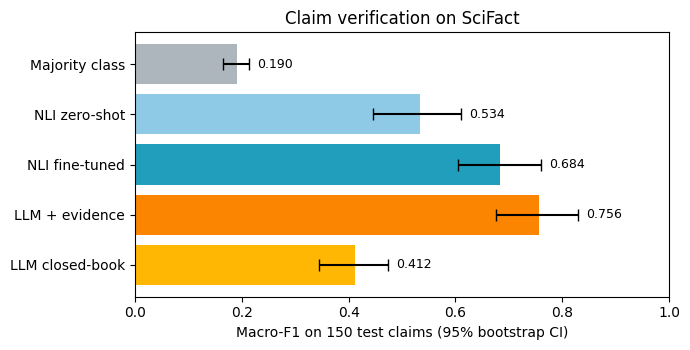

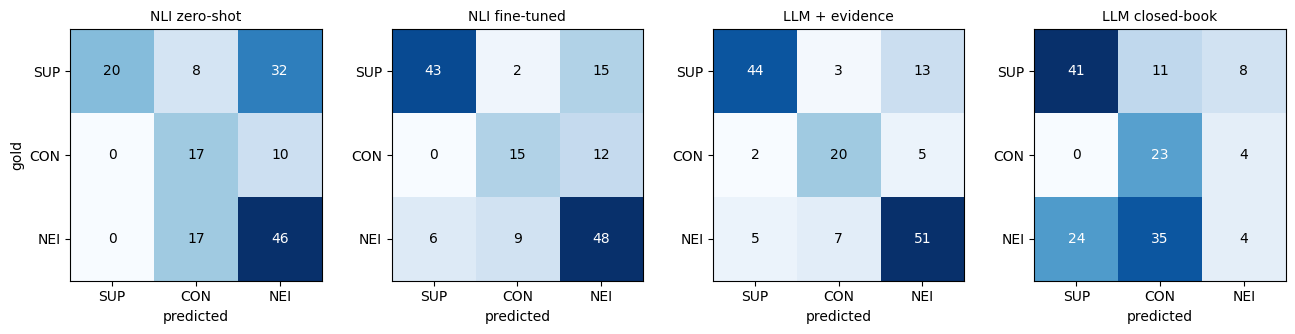

In [29]:
colors = {"Majority class": "#adb5bd", "NLI zero-shot": "#8ecae6", "NLI fine-tuned": "#219ebc",
          "LLM + evidence": "#fb8500", "LLM closed-book": "#ffb703"}
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(results))
ax.barh(y, results.macro_f1, color=[colors[s] for s in results.System],
        xerr=[np.clip(results.macro_f1 - results.ci_low, 0, None), np.clip(results.ci_high - results.macro_f1, 0, None)], capsize=4)
for yi, v, hi in zip(y, results.macro_f1, results.ci_high):
    ax.text(max(v, hi) + 0.015, yi, f"{v:.3f}", va="center", fontsize=9)
ax.set_yticks(y, results.System); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_xlabel(f"Macro-F1 on {EVAL_N} test claims (95% bootstrap CI)")
ax.set_title("Claim verification on SciFact")
plt.tight_layout(); plt.savefig(f"{OUT}/macro_f1.png", dpi=150); plt.show()

shown = [s for s, _ in SYSTEMS if s != "Majority class"]
fig, axes = plt.subplots(1, len(shown), figsize=(3.3 * len(shown), 3.2))
axes = np.atleast_1d(axes)
for ax, s in zip(axes, shown):
    cm = confusion_matrix([c["label"] for c in eval_claims], [x["label"] for x in preds[s][:EVAL_N]], labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(3), ["SUP", "CON", "NEI"]); ax.set_yticks(range(3), ["SUP", "CON", "NEI"])
    ax.set_title(s, fontsize=10); ax.set_xlabel("predicted")
axes[0].set_ylabel("gold")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrices.png", dpi=150); plt.show()

## 8. Error analysis: where does each pipeline fail?
**What:** every wrong answer is assigned to the stage that caused it:
- **Retrieval miss:** no gold abstract in the top 3, so the verifier never had a chance.
- **Sentence-selection miss:** the right abstract was found, but not the right sentence.
- **Missed verdict:** the gold sentence was there, but the verifier said NEI.
- **Flipped label:** the gold sentence was there, but the verifier said SUPPORT when the answer was CONTRADICT, or vice versa.
- **Verdict on NEI claim:** the claim has no evidence, but the verifier committed to an answer anyway.

This shows which component to improve next.

,NLI zero-shot,NLI fine-tuned,LLM + evidence
Retrieval miss,8,7,7
Sentence-selection miss,10,7,5
Missed verdict (said NEI),25,13,6
Flipped label,7,2,5
Verdict on NEI claim,17,15,12


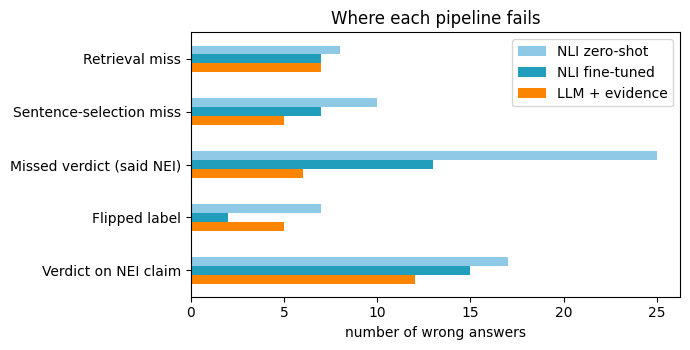

146 failures saved to results/failures.csv.

[Verdict on NEI claim] gold=NEI pred=CONTRADICT
  CLAIM: High levels of copeptin decrease risk of diabetes.
  EVIDENCE: 4.1 mosmol/kg, and copeptin decreased from 6.2 +/- || When compared with the lowest quartile, the fourth quartiles of fructosamine and glycated albumin were significantly associated with diabetes risk (hazard ratio [HR] 3.99 [95% CI 1.93-8.28] and 5.

[Sentence-selection miss] gold=SUPPORT pred=NEI
  CLAIM: Tetraspanin-3 is a causative factor in the development of acute myelogenous leukemia
  EVIDENCE: Here, we show that Tetraspanin 3 is a target of the RNA binding protein Musashi 2, which plays a key role in AML. || Acute Myelogenous Leukemia (AML) is an aggressive cancer that strikes both adults and children and is frequently resistant to therapy

[Missed verdict (said NEI)] gold=CONTRADICT pred=NEI
  CLAIM: Occupancy of ribosomes by IncRNAs do not make functional peptides.
  EVIDENCE: However, a recent study of ribosome 

In [30]:
ERROR_CATS = ["Retrieval miss", "Sentence-selection miss", "Missed verdict (said NEI)", "Flipped label", "Verdict on NEI claim"]

def categorize(c, x):
    if x["label"] == c["label"]:
        return None
    if c["label"] == "NEI":
        return "Verdict on NEI claim"
    if not set(c["rank"][BEST_RETRIEVER][:TOP_DOCS]) & c["gold_docs"]:
        return "Retrieval miss"
    if not any((e["doc"], e["sent"]) in c["gold_sents"] for e in c["evidence"]):
        return "Sentence-selection miss"
    return "Missed verdict (said NEI)" if x["label"] == "NEI" else "Flipped label"

ev_systems = [s for s, ev in SYSTEMS if ev]
err = pd.DataFrame({s: pd.Series([categorize(c, x) for c, x in zip(eval_claims, preds[s][:EVAL_N])]).value_counts()
                    for s in ev_systems}).reindex(ERROR_CATS).fillna(0).astype(int)
display(err)

ax = err.plot(kind="barh", figsize=(7, 3.6), color=[colors[s] for s in ev_systems])
ax.invert_yaxis(); ax.set_xlabel("number of wrong answers"); ax.set_title("Where each pipeline fails")
plt.tight_layout(); plt.savefig(f"{OUT}/error_breakdown.png", dpi=150); plt.show()

failure_rows = []
for s in ev_systems:
    for c, x in zip(eval_claims, preds[s][:EVAL_N]):
        cat = categorize(c, x)
        if cat:
            failure_rows.append(dict(system=s, category=cat, claim=c["claim"], gold=c["label"], predicted=x["label"],
                                     evidence=" || ".join(e["text"] for e in c["evidence"])))
failures = pd.DataFrame(failure_rows)
failures.to_csv(f"{OUT}/failures.csv", index=False)
print(f"{len(failures)} failures saved to {OUT}/failures.csv.\n")
for _, r in failures[failures.system == "NLI fine-tuned"].head(6).iterrows():
    print(f"[{r.category}] gold={r.gold} pred={r.predicted}\n  CLAIM: {r.claim}\n  EVIDENCE: {r.evidence[:250]}\n")

## 9. README and requirements
**What:** Generates the README and requirements from the computed results

In [34]:
def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(str(v) for v in r) + " |")
    return "\n".join(lines)

R = results.set_index("System")
ret_test = retrieval_df[retrieval_df.Split == "test"].drop(columns="Split")
ret_md = ret_test.assign(**{c: ret_test[c].map(lambda v: f"{v:.3f}") for c in ret_test.columns if c.startswith("Recall")})
best_sys = R.macro_f1.drop("Majority class").idxmax()
best_ev = R.loc[ev_systems].macro_f1.idxmax()
top_err = err[best_ev].idxmax()

findings = [f"- **Best system:** {best_sys}, macro-F1 {R.macro_f1[best_sys]:.3f} (95% CI {R.ci_low[best_sys]:.3f}–{R.ci_high[best_sys]:.3f})."]
findings.append(f"- **Fine-tuning on SciFact** moved the NLI verifier from {R.macro_f1['NLI zero-shot']:.3f} to {R.macro_f1['NLI fine-tuned']:.3f} macro-F1"
                + (f" ({ft_mean:.3f} ± {ft_std:.3f} over {len(ft_runs)} seeds)." if len(ft_runs) > 1 else "."))
if "LLM + evidence" in R.index:
    findings.append(f"- **Retrieval for the LLM:** closed-book {R.macro_f1['LLM closed-book']:.3f} vs. with evidence {R.macro_f1['LLM + evidence']:.3f} macro-F1.")
    findings.append(f"- **Grounding:** ungrounded verdicts were {R.ungrounded['NLI fine-tuned']:.1%} for the fine-tuned NLI model and {R.ungrounded['LLM + evidence']:.1%} for the LLM with evidence.")
findings.append(f"- **Most common failure** for {best_ev}: {top_err.lower()} ({err[best_ev][top_err]} of {err[best_ev].sum()} errors).")
findings.append(f"- **Retrieval:** {RETRIEVERS[BEST_RETRIEVER]} was chosen on validation; on test it finds a gold abstract in the top {TOP_DOCS} for {doc_hit_rate(eval_claims):.1%} of claims with evidence.")

llm_line = f"`{LLM_MODEL}` via an OpenAI-compatible API, temperature 0" if RUN_LLM else "not run"
readme = f"""# Evidence-Grounded Claim Verification: Retrieval + NLI vs. LLM

A retrieve-then-verify fact-checking pipeline benchmarked on [SciFact](https://github.com/allenai/scifact): {len(corpus):,} research abstracts and expert-written scientific claims labelled SUPPORT, CONTRADICT, or NOT ENOUGH INFO. It compares retrievers, then compares a zero-shot NLI model, a fine-tuned NLI model and an LLM on identical evidence, and measures how often each one gives a verdict it can't back up.

```mermaid
flowchart LR
    A[Claim] --> B[BM25]
    A --> C[Dense: bge-small + FAISS]
    B --> D[Reciprocal Rank Fusion]
    C --> D
    D --> E[Top-{TOP_DOCS} abstracts]
    E --> F[Cross-encoder sentence selection]
    F --> G[Top-{TOP_SENTS} evidence sentences]
    G --> H1[DeBERTa-v3 NLI: zero-shot]
    G --> H2[DeBERTa-v3 NLI: fine-tuned]
    G --> H3[LLM + evidence]
    A --> H4[LLM closed-book]
```

## Results

Scored on {EVAL_N} held-out claims (SciFact dev set; official test labels are hidden). Thresholds and the retriever were chosen on a separate {len(val_claims)}-claim validation split.

{md_table(pretty)}

![Macro-F1](results/macro_f1.png)

**Key findings**

{chr(10).join(findings)}

### Retrieval (test set)

{md_table(ret_md)}

### Where the pipelines fail

![Error breakdown](results/error_breakdown.png)

{md_table(err.reset_index().rename(columns={"index": "Error type"}))}

## Method

| Stage | Choice |
|---|---|
| Retrieval | BM25 (`rank_bm25`), dense `{DENSE_MODEL}` + FAISS, hybrid via Reciprocal Rank Fusion |
| Sentence selection | `{RERANK_MODEL}`, top {TOP_SENTS} sentences from top {TOP_DOCS} abstracts |
| NLI verifier | `{NLI_MODEL}`; max entailment/contradiction over sentences, NEI below a validation-tuned threshold |
| Fine-tuning | Gold rationales + retrieved hard negatives, {FT_EPOCHS} epochs, lr {FT_LR}, {len(FT_SEEDS)} seed(s) |
| LLM verifier | {llm_line} |

**Metrics.** Macro-F1 with 1,000-sample bootstrap CIs; *strict accuracy* requires the cited sentence to be a gold rationale; *ungrounded verdicts* is the share of SUPPORT/CONTRADICT answers whose cited evidence is not a gold rationale.

## Run it

Open `claim_verification.ipynb` in Google Colab with a T4 GPU, add `LLM_API_KEY` to Colab Secrets, and Run all. The last section launches a Gradio demo that verifies any typed claim.

## Limitations

- {EVAL_N} test claims is small, which is why the confidence intervals are reported.
- One LLM was tested; results may differ for other models and prompts.
- Latency covers only the verifier step, not the shared retrieval.

## Data and citation

SciFact is released under CC BY-NC 2.0. Wadden et al., *Fact or Fiction: Verifying Scientific Claims*, EMNLP 2020.
"""
with open("README.md", "w") as f:
    f.write(readme)

with open("requirements.txt", "w") as f:
    f.write("rank_bm25\nfaiss-cpu\nsentence-transformers\ntransformers\ntorch\nsentencepiece\nprotobuf\nopenai\ngradio\nscikit-learn\npandas\nmatplotlib\n")

bundle = "claim-verification-results"
os.makedirs(bundle, exist_ok=True)
for f in ["README.md", "requirements.txt"]:
    shutil.copy(f, bundle)
shutil.copytree(OUT, f"{bundle}/results", dirs_exist_ok=True)
shutil.make_archive(bundle, "zip", bundle)
try:
    from google.colab import files
    files.download(f"{bundle}.zip")
except Exception:
    print(f"\nSaved {bundle}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Demo
**What:** a small web app. Given any claim, it retrieves abstracts, selects evidence, and runs the fine-tuned verifier. `share=True` creates a temporary public link for sharing the demo.

In [32]:
def verify(claim):
    claim = (claim or "").strip()
    if not claim:
        return "Type a claim first."
    c = {"claim": claim}
    br, dr = bm25_search(claim), dense_search([claim])[0]
    c["rank"] = {"bm25": br, "dense": dr, "hybrid": rrf([br, dr])}
    select_evidence([c], BEST_RETRIEVER)
    S, _ = nli_scores(nli_ft, [c])
    label, idx, conf = nli_decide(S[0], tau_ft)
    lines = [f"### Verdict: **{label}** (confidence {conf:.2f})", "", "**Evidence considered:**"]
    for j, e in enumerate(c["evidence"]):
        mark = "➡️ " if j in idx else ""
        lines.append(f"- {mark}{e['text']}  \n  <sub>{corpus[e['doc']]['title']}</sub>")
    return "\n".join(lines)

print(verify(test_claims[0]["claim"])[:600])

### Verdict: **CONTRADICT** (confidence 0.81)

**Evidence considered:**
- 4.1 mosmol/kg, and copeptin decreased from 6.2 +/-  
  <sub>Changes in plasma copeptin, the c-terminal portion of arginine vasopressin during water deprivation and excess in healthy subjects.</sub>
- ➡️ When compared with the lowest quartile, the fourth quartiles of fructosamine and glycated albumin were significantly associated with diabetes risk (hazard ratio [HR] 3.99 [95% CI 1.93-8.28] and 5.22 [2.49-10.94], respectively).  
  <sub>Alternative Markers of Hyperglycemia and Risk of Diabetes</sub>
- 4.3 mosmol/kg, and a


In [33]:
!pip -q install gradio
import gradio as gr
gr.Interface(
    fn=verify,
    inputs=gr.Textbox(label="Scientific claim", lines=2),
    outputs=gr.Markdown(),
    title="Evidence-grounded claim verifier",
    description="Retrieves evidence from 5,183 SciFact abstracts and verifies the claim with a fine-tuned DeBERTa-v3 NLI model.",
    examples=[[c["claim"]] for c in test_claims[:4]],
).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b70cfa260b6a7937db.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
